In [1]:
import sys

# Append the parent dir to search path to allow imports from src
sys.path.append("..")

# Tell the Notebook to reload changed code in own packages automatically
%load_ext autoreload
%autoreload 2

# Exploratory Data Analysis
## Basic overview of the images

In [2]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')

train_files = list(TRAIN_PATH.glob('*.jpg'))
test_files = list(TEST_PATH.glob('*.jpg'))

train_files_count = len(train_files)
test_files_count = len(test_files)

test_percent = 100 * test_files_count // (test_files_count + train_files_count)

print(f'There are {train_files_count} training images and {test_files_count} '
      f'test images\n\nThis makes a test size of {test_percent}%.')


There are 5546 training images and 3698 test images

This makes a test size of 40%.


## Basic overview of the labels (DataFrame of `train.csv`)

In [3]:
import pandas as pd

df = pd.read_csv('../data/raw/train.csv')
display(df.shape)
display(df.info())
display(df.head())


(22184, 2)

<class 'pandas.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Image_Label    22184 non-null  str  
 1   EncodedPixels  11836 non-null  str  
dtypes: str(2)
memory usage: 346.8 KB


None

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


## Analysis of the labels DataFrame

- The `df` contains 2 columns. Both are of type `object`: `Image_label` and `EncodedPixels`
- There are 4 rows per image, one for each of the categories **Fish**, **Flower**, **Gravel** and **Sugar**
- These categories are appended to the file name in the column `Image_Label`. So, this column contains two different informations that should be separated/split.
- The `EncodedPixels` :
  - Is `NaN` when a picture is not labeled for the category which is appended to the filename.
  - But if there is no `NaN` then the `EncodedPixels` column contains the **RLE encoded*** mask of the image. Within this rectangular area scientists marked the appropriate category when they spotted it in the image. Origin of this investigation seems to be [this paper](https://www.researchgate.net/publication/342432947_Combining_Crowdsourcing_and_Deep_Learning_to_Explore_the_Mesoscale_Organization_of_Shallow_Convection).


> **RLE Encoded*** The [Kaggle page](https://www.kaggle.com/competitions/understanding_cloud_organization/overview/evaluation) states about the EncodedPixels:
> 
> In order to reduce the submission file size, our metric uses run-length encoding on the pixel values. Instead of submitting an exhaustive list of indices for your segmentation, you will submit pairs of values that contain a start position and a run length. E.g. '1 3' implies starting at pixel 1 and running a total of 3 pixels (1,2,3).
> 
> The competition format requires a space delimited list of pairs. For example, '1 3 10 5' implies pixels 1,2,3,10,11,12,13,14 are to be included in the mask. The metric checks that the pairs are sorted, positive, and the decoded pixel values are not duplicated. The pixels are numbered from top to bottom, then left to right: 1 is pixel (1,1), 2 is pixel (2,1), etc.

## Adding an own column for the labels

For counting etc it is impractical to have the labels attached to the file name. It should be moved to its own column.

In [4]:
df['Label'] = df['Image_Label'].str.split('_', n=1).str[1]
df['Image_Label'] = df['Image_Label'].str.split('_', n=1).str[0]
df = df.rename({'Image_Label': 'Image'}, axis=1)
df.head()

,Image,EncodedPixels,Label
0,0011165.jpg,20056 257 20440 257 20824 257 21208 257 21592 ...,Fish
1,0011165.jpg,102135 1 102245 275 102629 275 103013 275 1033...,Flower
2,0011165.jpg,NaN,Gravel
3,0011165.jpg,NaN,Sugar
4,002be4f.jpg,17668 241 18051 242 18435 242 18819 242 19203 ...,Fish


## What are the shares of the distinct cloud types?

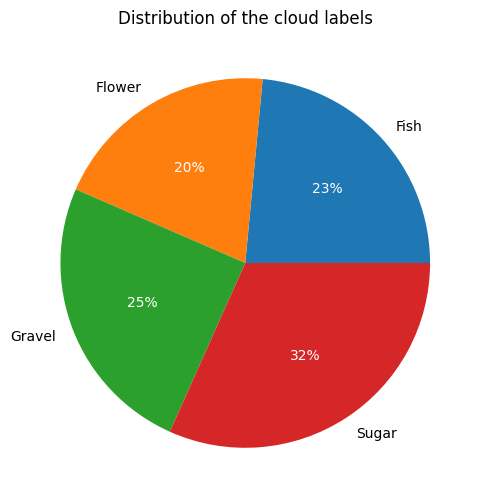

In [5]:
import matplotlib.pyplot as plt

df_no_na = df.dropna()
df_fish = df_no_na[df_no_na['Label']=='Fish']
df_flower = df_no_na[df_no_na['Label']=='Flower']
df_gravel = df_no_na[df_no_na['Label']=='Gravel']
df_sugar = df_no_na[df_no_na['Label']=='Sugar']

fish_count = len(df_fish)
flower_count = len(df_flower)
gravel_count = len(df_gravel)
sugar_count = len(df_sugar)

plt.figure(figsize=(6, 6))
wedges, texts, *rest = plt.pie(
    x=[fish_count, flower_count, gravel_count, sugar_count],
    labels=['Fish', 'Flower', 'Gravel', 'Sugar'],
    autopct='%.0f%%',   # Show percentages - and with no decimals
)

# Set the percentages colors to 'white'
if len(rest) > 0:           # The autotexts can be found in `rest[0]` - but only
    autotexts = rest[0]     #  if the `autopct` param is set in the chart.
    for autotext in autotexts:
        autotext.set_color('white')

    plt.title('Distribution of the cloud labels')
    plt.show()


<div class="alert alert-success">✅ Sugar has a much larger share than the others, which have fairly similar shares among themselves. <b>Could that be relevant - maybe in model selection?</b></div>

## Are there any images that have no label?



In [6]:
labels_per_image = df.groupby('Image')['EncodedPixels'].count()
unlabeled_images = labels_per_image[labels_per_image == 0].index.to_list()
print('Number of pictures without labels:', len(unlabeled_images))

Number of pictures without labels: 0


<div class="alert alert-success">✅ In the labels DataFrame there are no images without labels.</div>

## Are there images with multiple labels?

In [7]:
images_per_label_count = labels_per_image.value_counts().sort_index()
images_per_label_count

EncodedPixels
1    1348
2    2372
3    1560
4     266
Name: count, dtype: int64

<div class="alert alert-success">✅ As it turns out, <b>images with only one cloud type are the exception rather than the rule</b>: about three out of four images contain <b>multiple labels</b>.</div>

Let's visualize this fact:

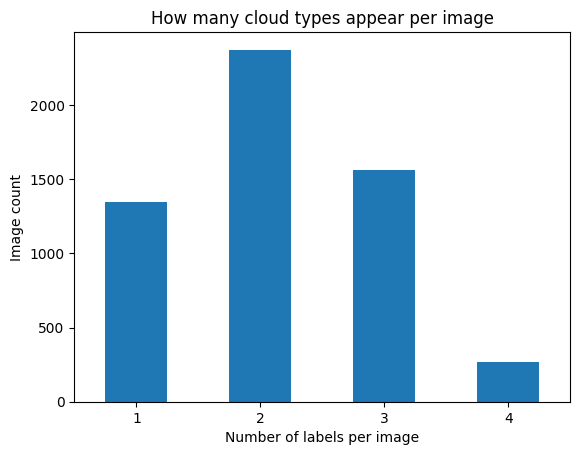

In [8]:
ax = images_per_label_count.plot.bar(rot=0)
ax.set_xlabel('Number of labels per image')
ax.set_ylabel('Image count')
ax.set_title('How many cloud types appear per image')
plt.show()

## How does the images look?

In [9]:
from src.data.image_masks import ImageMasks
from src.visualization.visualize import display_masked_image


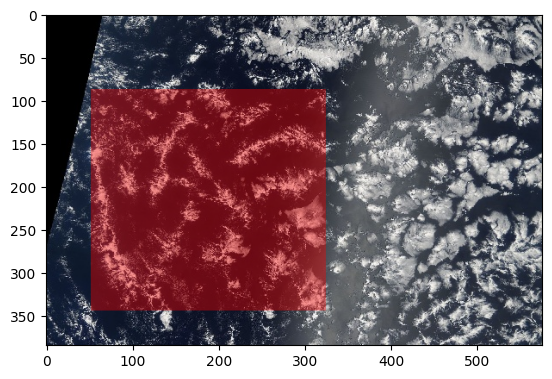

In [21]:
from src.visualization.visualize import draw_mask_on_image

image_masks = ImageMasks(df, 0, TRAIN_PATH)
result = draw_mask_on_image(image_masks.get_fish_mask(), color=(255, 0, 0), alpha=0.4)
plt.imshow(result)

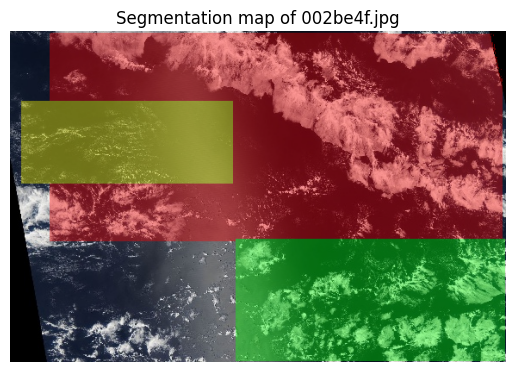

In [24]:
from src.visualization.visualize import draw_segmap_on_image

# Load all 4 label-masks (fish, flower, gravel, sugar) of one image
masks = ImageMasks(df, image_id=4, image_path=TRAIN_PATH)

# `ImageMasks` builds the combined segmentation map itself, the colors default
# to `LABEL_COLORS`.
# NOTE: Where masks overlap only the label with the highest class id is shown.
result = draw_segmap_on_image(masks, alpha=0.4)

plt.imshow(result)
plt.axis('off')
plt.title(f'Segmentation map of {masks.get_name()}')
plt.show()


# Display the first 3 images (with all masks)

In [ ]:
from IPython.display import Markdown, display

# How to get a list of the *distinct* images in df['Image'] from Pandas?
# 
all_image_names = df['Image'].unique().tolist()

for i in range(3):
    image_masks = ImageMasks(df, i, TRAIN_PATH)
    display(Markdown(f'## Image {image_masks.get_name()}'))
    for image_mask in image_masks.get_all_masks():
        display_masked_image(image_mask)


['0011165.jpg', '002be4f.jpg', '0031ae9.jpg']

In [ ]:
# def create_segmap(image_id):
#     '''
#     Helper function to create a segmentation map for an image by image filename
#     '''
#     # open the image
#     image = np.asarray(Image.open(image_id))
    
#     # get masks for different classes
#     fish_mask = get_mask_by_image_id(image_id, 'Fish')
#     flower_mask = get_mask_by_image_id(image_id, 'Flower')
#     gravel_mask = get_mask_by_image_id(image_id, 'Gravel')
#     sugar_mask = get_mask_by_image_id(image_id, 'Sugar')
    
#     # label numpy map with 4 classes
#     segmap = np.zeros((image.shape[0], image.shape[1]), dtype=np.int32)
#     segmap = np.where(fish_mask == 1, 1, segmap)
#     segmap = np.where(flower_mask == 1, 2, segmap)
#     segmap = np.where(gravel_mask == 1, 3, segmap)
#     segmap = np.where(sugar_mask == 1, 4, segmap)
    
#     # create a segmantation map
#     segmap = SegmentationMapOnImage(segmap, shape=image.shape, nb_classes=5)
    
#     return segmap

# def draw_labels(image, np_mask, label):
#     '''
#     Function to add labels to the image.
#     '''
#     if np.sum(np_mask) > 0:
#         x,y = 0,0
#         x,y = np.argwhere(np_mask==1)[0]
                
#         image = imgaug.imgaug.draw_text(image, x, y, label, color=(255, 255, 255), size=50)
#     return image

# def draw_segmentation_maps(image_id):
#     '''
#     Helper function to draw segmantation maps and text.
#     '''
#     # open the image
#     image = np.asarray(Image.open(image_id))
    
#     # get masks for different classes
#     fish_mask = get_mask_by_image_id(image_id, 'Fish')
#     flower_mask = get_mask_by_image_id(image_id, 'Flower')
#     gravel_mask = get_mask_by_image_id(image_id, 'Gravel')
#     sugar_mask = get_mask_by_image_id(image_id, 'Sugar')
    
#     # label numpy map with 4 classes
#     segmap = create_segmap(image_id)
    
#     # draw the map on image
#     image = np.asarray(segmap.draw_on_image(np.asarray(image))).reshape(np.asarray(image).shape)
    
#     image = draw_labels(image, fish_mask, 'Fish')
#     image = draw_labels(image, flower_mask, 'Flower')
#     image = draw_labels(image, gravel_mask, 'Gravel')
#     image = draw_labels(image, sugar_mask, 'Sugar')
    
#     return image

# # helper function to visualize several segmentation maps on a single image
# def visualize_several_maps(image_id):
#     '''
#     Function to visualize several segmentation maps.
#     INPUT:
#         image_id - filename of the image
#     '''
#     # open the image
#     image = np.asarray(Image.open(image_id))
    
#     # draw segmentation maps and labels on image
#     image = draw_segmentation_maps(image_id)
    
#     # visualize the image and map
#     side_by_side = np.hstack([
#         image
#     ])
    
#     labels = get_labels(image_id.split('/')[-1])

#     fig, ax = plt.subplots(figsize=(15, 7))
#     ax.axis('off')
#     plt.title('Segmentation maps:' + labels)
#     plt.legend()
    
#     ax.imshow(side_by_side)